In [10]:
from ultralytics import YOLO
import os
import numpy as np
import cv2
import supervision as sv
import matplotlib.pyplot as plt

In [3]:
model = YOLO('../models/best_new.pt')

In [ ]:
def read_frames(frames_path):
        # Read the frames from the specified path
        frames = []
        count = 0
        for filename in sorted(os.listdir(frames_path)):
            if filename.endswith(".jpg") or filename.endswith(".png"):
                frame_path = os.path.join(frames_path, filename)
                frame = cv2.imread(frame_path)
                # new_frame = cv2.resize(frame, (640, 640))
                frames.append(frame)
                if count == 50:
                    break
                count += 1
        return frames

In [8]:
frames = read_frames('../badr/all/')

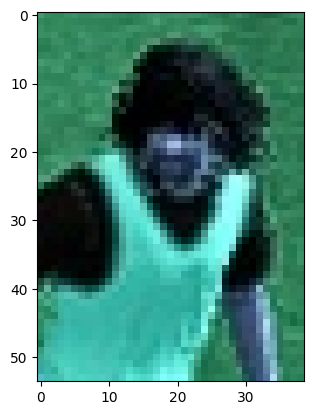

In [ ]:
frame = frames[0]
detection = model(frame ,verbose = False) #BADR MIDO

cls_names = detection[0].names
# cls_names_ball = detection_ball[0].names
cls_names_inv = {v: k for k, v in cls_names.items()}
# cls_names_inv_ball = {v: k for k, v in cls_names_ball.items()}

# Convert to supervision Detection format
detection_supervision = sv.Detections.from_ultralytics(detection[0])
detections_nms = detection_supervision.with_nms(threshold=0.5, class_agnostic=True)
# detection_supervision_ball = sv.Detections.from_ultralytics(detection_ball[0])

for i,frame_detection in enumerate(detections_nms):
    bbox = frame_detection[0].tolist()
    x1, y1, x2, y2 = int(bbox[0]), int(bbox[1]), int(bbox[2]), int(bbox[3])
    cls_id = frame_detection[3]
    track_id = i
    conf = frame_detection[2]
    

    if cls_id == cls_names_inv["player"] or cls_id == cls_names_inv["referee"] or cls_id == cls_names_inv["goalkeeper"]:
        
                    